# AQI Prediction for Indian Cities: Exploratory Data Analysis (EDA)

**What this notebook does:** it explores the raw dataset before any modelling, so that every cleaning and modelling decision in `02_modeling.ipynb` is backed by evidence.

**How to study it:** each section has three parts:
1. a short note on **what we check and why**,
2. the **code**,
3. an **Insight** cell that answers "so what?" for the project.

Sections:
0. Problem statement
1. Load the data and understand every column
2. Missing values
3. Duplicates
4. The target (AQI) and its extreme values
5. Relationships between pollutants and AQI
6. Trends over time (year, month, day of week)
7. City comparison
8. Class balance of AQI categories
9. Summary: what EDA tells us to do in preprocessing

## 0. Problem Statement

**Who uses it:** ordinary people, such as commuters, parents, outdoor workers, students, the elderly and anyone with asthma or heart or lung conditions. They need to know **tomorrow's** air quality to decide whether to limit outdoor time, move exercise indoors, wear a mask, or keep children and elderly people inside.

**What is predicted:** tomorrow's AQI for an Indian city. This is a **regression** task (AQI is a number). The inputs are today's pollutant readings (PM2.5, PM10, NO2, SO2, CO, O3, NH3) and date features (month, day of week, season). The predicted AQI is then converted to a category (Good to Severe) so the app can show a plain-language health message.

**How success is measured:** mainly by **MAE** (Mean Absolute Error), the average number of AQI points the forecast is off by. It is easy to explain to a non-technical user ("on average we are off by about X points"). **RMSE** (which punishes big misses more) and **R²** (share of variation explained) are reported alongside it. Every model must beat a simple baseline that always predicts the average.

### Pollutants used as inputs

| Pollutant | Full name | Simple definition |
|---|---|---|
| PM2.5 | Particulate Matter below 2.5 micrometres | Very fine particles from vehicle exhaust, burning and industry. Small enough to enter the lungs and bloodstream. |
| PM10 | Particulate Matter below 10 micrometres | Coarser particles such as road and construction dust. They irritate the nose, throat and lungs. |
| NO2 | Nitrogen Dioxide | A gas from vehicles and power plants. It irritates the airways and worsens asthma. |
| SO2 | Sulphur Dioxide | A gas from burning coal and industrial fuel. It affects breathing, especially in people with asthma. |
| CO | Carbon Monoxide | A gas from incomplete burning of fuel, mostly vehicles. It reduces the oxygen carried in the blood. |
| O3 | Ground-level Ozone | Formed when sunlight reacts with other pollutants. It irritates the lungs and is worse on sunny days. |
| NH3 | Ammonia | A gas mostly from agriculture, fertilisers and waste. It irritates the eyes, nose and throat. |

## 1. Load the data

**What and why:** we load `city_day.csv` (Kaggle: *Air Quality Data in India 2015-2020*). `parse_dates=["Date"]` turns the Date text into real dates so we can sort, shift and group by time. The file path comes from `src/config.py`, so this notebook runs from any folder without a hard-coded local path.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ folder importable, whether this notebook is run
# from the project root or from the notebooks/ folder.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import DATA_PATH, POLLUTANTS

sns.set_theme(style="whitegrid")

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


**Insight:** The dataset has 29,531 rows and 16 columns, with one row per city per day. The pollutant columns already show missing values (NaN) in the first rows, so cleaning will be needed.

### 1.1 Understanding every column

**What and why:** before analysing anything, we check each column's type and meaning. A model can only be explained if every input is understood.

In [2]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "unique": df.nunique(),
})
print(info)
print("\nCities:", df["City"].nunique(), "| Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

                     dtype  non_null  unique
City                   str     29531      26
Date        datetime64[us]     29531    2009
PM2.5              float64     24933   11716
PM10               float64     18391   12571
NO                 float64     25949    5776
NO2                float64     25946    7404
NOx                float64     25346    8156
NH3                float64     19203    5922
CO                 float64     27472    1779
SO2                float64     25677    4761
O3                 float64     25509    7699
Benzene            float64     23908    1873
Toluene            float64     21490    3608
Xylene             float64     11422    1561
AQI                float64     24850     829
AQI_Bucket             str     24850       6

Cities: 26 | Date range: 2015-01-01 to 2020-07-01


| Column | Type | Meaning |
|---|---|---|
| City | text | One of 26 Indian cities |
| Date | date | The day of the reading |
| PM2.5, PM10 | number (µg/m³) | Particulate matter (fine and coarse dust) |
| NO, NO2, NOx | number (µg/m³) | Nitrogen oxides, mainly from traffic |
| NH3 | number (µg/m³) | Ammonia |
| CO | number (mg/m³) | Carbon monoxide (note: different unit, so values are small) |
| SO2 | number (µg/m³) | Sulphur dioxide |
| O3 | number (µg/m³) | Ground-level ozone |
| Benzene, Toluene, Xylene | number (µg/m³) | Volatile organic compounds |
| AQI | number | Air Quality Index for that day (our target, shifted to tomorrow) |
| AQI_Bucket | text | AQI category (Good, Satisfactory, Moderate, Poor, Very Poor, Severe) |

**Insight:** Every pollutant column is numeric and only City and AQI_Bucket are text. The dataset covers 26 cities from 2015 to mid-2020. AQI_Bucket is just AQI converted to a category, so it would leak the answer and must never be used as an input.

## 2. Missing values

**What and why:** missing values must be handled before modelling. The amount missing per column tells us which columns are usable and which strategy to pick.

Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI           15.9
AQI_Bucket    15.9
PM2.5         15.6
NOx           14.2
O3            13.6
SO2           13.1
NO2           12.1
NO            12.1
CO             7.0
Date           0.0
City           0.0
dtype: float64


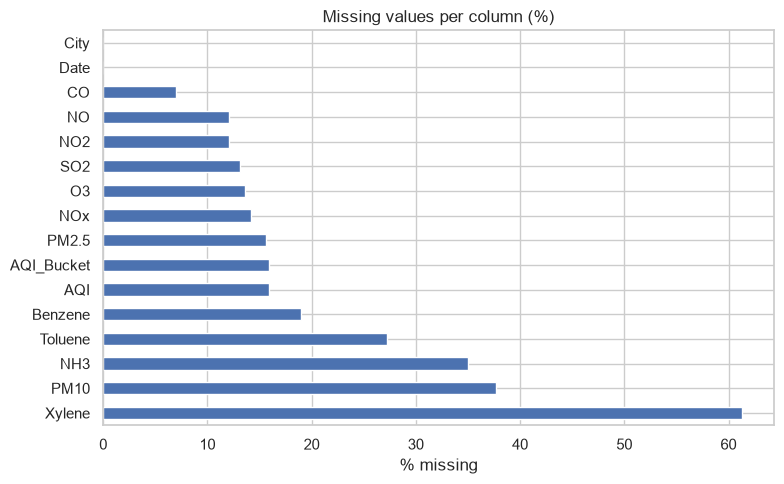

In [3]:
missing_pct = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing_pct)

missing_pct.plot(kind="barh", figsize=(8, 5), title="Missing values per column (%)")
plt.xlabel("% missing")
plt.tight_layout()
plt.show()

**Insight:** Xylene (61.3%), PM10 (37.7%), NH3 (35.0%) and Toluene (27.2%) have the most missing values, and AQI itself is missing in 15.9% of rows. Deleting every row with a gap would throw away most of the data, so missing pollutant values will be filled (with medians learned from training data only), and rows without a target AQI will be dropped. Benzene, Toluene and Xylene are left out of the model because they are mostly missing.

### 2.1 Coverage per city

**What and why:** missingness may not be spread evenly. If some cities are mostly empty, the model will know little about them.

In [4]:
city_summary = df.groupby("City").agg(
    rows=("Date", "count"),
    start=("Date", "min"),
    end=("Date", "max"),
    aqi_missing_pct=("AQI", lambda s: round(s.isna().mean() * 100, 1)),
)
print(city_summary.sort_values("aqi_missing_pct", ascending=False))

                    rows      start        end  aqi_missing_pct
City                                                           
Mumbai              2009 2015-01-01 2020-07-01             61.4
Jorapokhar          1169 2017-04-20 2020-07-01             34.0
Shillong             310 2019-08-27 2020-07-01             33.9
Ahmedabad           2009 2015-01-01 2020-07-01             33.6
Talcher              925 2017-12-20 2020-07-01             24.5
Brajrajnagar         938 2017-12-07 2020-07-01             24.0
Patna               1858 2015-06-01 2020-07-01             21.5
Visakhapatnam       1462 2016-07-01 2020-07-01             19.9
Gurugram            1679 2015-11-27 2020-07-01             13.5
Amaravati            951 2017-11-24 2020-07-01             11.6
Coimbatore           386 2019-06-12 2020-07-01             10.9
Amritsar            1221 2017-02-27 2020-07-01              7.8
Kolkata              814 2018-04-10 2020-07-01              7.4
Hyderabad           2006 2015-01-04 2020

**Insight:** Mumbai has the worst AQI coverage (61.4% missing), while Delhi has the best (0.5%). Cities also differ a lot in size, from about 2,000 rows for the longest histories to only 113 for Aizawl, so predictions for thinly covered cities will be less reliable.

## 3. Duplicates

**What and why:** a duplicated City + Date pair would break the "tomorrow" target, because shifting by one row would no longer mean "the next day".

In [5]:
print("Duplicate City+Date:", df.duplicated(subset=["City", "Date"]).sum())

Duplicate City+Date: 0


**Insight:** There are no duplicate City and Date rows, so each city has at most one row per day. This matters because tomorrow's AQI will be created by shifting AQI back one day within each city.

## 4. Target variable: AQI

**What and why:** the target's shape tells us which metric to use, whether outliers exist, and whether the data needs cleaning.

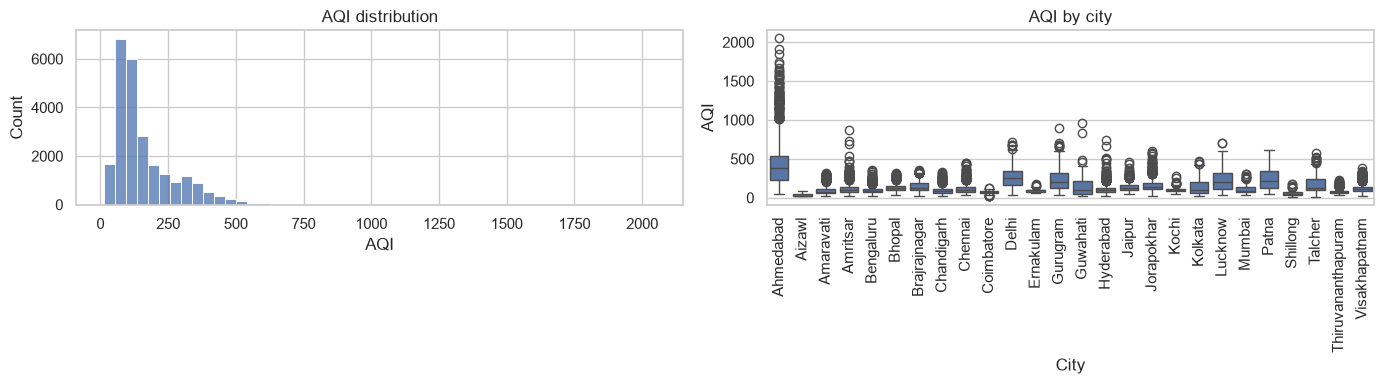

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["AQI"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("AQI distribution")
sns.boxplot(data=df, x="City", y="AQI", ax=axes[1])
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("AQI by city")
plt.tight_layout()
plt.show()

**Insight:** AQI is strongly right-skewed. Most days fall between about 80 and 150, but a long tail runs past 2,000, which is far above the official 500 limit. Ahmedabad is the clear outlier among cities.

### 4.1 Extreme AQI values (above 500)

**What and why:** the official Indian AQI scale stops at 500, so values above it are suspicious and need a closer look.

In [7]:
print("AQI > 500:", (df["AQI"] > 500).sum())
print(df[df["AQI"] > 500]["City"].value_counts())
print(df["AQI"].describe())

AQI > 500: 543
City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
Name: count, dtype: int64
count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64


**Insight:** 543 of 24,850 AQI values (about 2.2%) are above 500, and Ahmedabad holds 412 of them. The mean (166) is well above the median (118), which confirms the skew.

### 4.2 Investigating extreme AQI values in Ahmedabad

**What and why:** outliers should be treated deliberately, not automatically. We first ask *why* Ahmedabad's values are so high.

In [8]:
ahd = df[(df["City"] == "Ahmedabad") & (df["AQI"] > 500)]
print(ahd["Date"].dt.year.value_counts().sort_index())
print(ahd[["Date", "PM2.5", "PM10", "AQI"]].head(10))

Date
2015     40
2016     11
2017     31
2018    184
2019    129
2020     17
Name: count, dtype: int64
         Date   PM2.5  PM10     AQI
30 2015-01-31   94.52   NaN   514.0
31 2015-02-01  135.99   NaN   782.0
32 2015-02-02  178.33   NaN   914.0
33 2015-02-03  139.70   NaN   660.0
43 2015-02-13  103.36   NaN   510.0
44 2015-02-14  177.33   NaN   761.0
46 2015-02-16   99.70   NaN   536.0
48 2015-02-18  100.79   NaN   592.0
50 2015-02-20  140.29   NaN   588.0
51 2015-02-21  239.96   NaN  1141.0


**Insight:** Ahmedabad's extreme values appear in every year but cluster in 2018 and 2019, which hold 313 of the 412. On the rows shown, PM10 is missing and AQI is far higher than PM2.5 alone would explain, so the values look suspicious.

### 4.3 Pollutants on extreme days vs normal days (Ahmedabad)

In [9]:
cols = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3"]
ahd_city = df[df["City"] == "Ahmedabad"]
print("Extreme days (AQI > 500):")
print(ahd_city[ahd_city["AQI"] > 500][cols].mean().round(1))
print("\nNormal days (AQI <= 500):")
print(ahd_city[ahd_city["AQI"] <= 500][cols].mean().round(1))

Extreme days (AQI > 500):
PM2.5     89.9
PM10     146.3
NO2       91.5
SO2       73.2
CO        42.6
O3        43.8
NH3        NaN
dtype: float64

Normal days (AQI <= 500):
PM2.5     58.0
PM10     104.1
NO2       46.3
SO2       48.1
CO        13.0
O3        37.2
NH3        NaN
dtype: float64


**Insight:** On Ahmedabad's extreme days every pollutant is higher, but CO stands out at 42.6 against 13.0 on normal days. NH3 is missing entirely for Ahmedabad.

### 4.4 Checking whether NO and CO are duplicated in Ahmedabad

**What and why:** CO is normally a small number (mg/m³), so a CO of 42.6 is odd. A common data-entry error is one column being copied into another, so we compare CO with NO.

In [10]:
ahd_city = df[df["City"] == "Ahmedabad"]
other = df[df["City"] != "Ahmedabad"]

print("Ahmedabad, rows where NO equals CO:", (ahd_city["NO"] == ahd_city["CO"]).sum(), "of", len(ahd_city))
print("Other cities, rows where NO equals CO:", (other["NO"] == other["CO"]).sum(), "of", len(other))

Ahmedabad, rows where NO equals CO: 1317 of 2009
Other cities, rows where NO equals CO: 5 of 27522


**Insight:** NO equals CO in 1,317 of Ahmedabad's 2,009 rows (66%), but in only 5 of 27,522 rows elsewhere. Ahmedabad's CO column is very likely a copy of NO.

### 4.5 Overlap between extreme AQI days and copied CO rows

In [11]:
ahd_city = df[df["City"] == "Ahmedabad"].copy()
ahd_city["no_eq_co"] = ahd_city["NO"] == ahd_city["CO"]
ahd_city["extreme"] = ahd_city["AQI"] > 500
print(pd.crosstab(ahd_city["extreme"], ahd_city["no_eq_co"]))

no_eq_co  False  True 
extreme               
False       692    905
True          0    412


**Insight:** All 412 of Ahmedabad's extreme AQI days have NO equal to CO. The extreme values are therefore likely artefacts of bad CO data, not real air quality. **Decision for preprocessing:** drop Ahmedabad's copied-CO rows and cap AQI at the official maximum of 500.

## 5. Relationships between pollutants and AQI

**What and why:** a model can only learn from inputs that are related to the target. A correlation matrix shows how strongly each pair of columns moves together (+1 = rise together, 0 = no linear link, -1 = opposite directions). We compute it **without** Ahmedabad's copied-CO rows, so the bad data found above does not distort it.

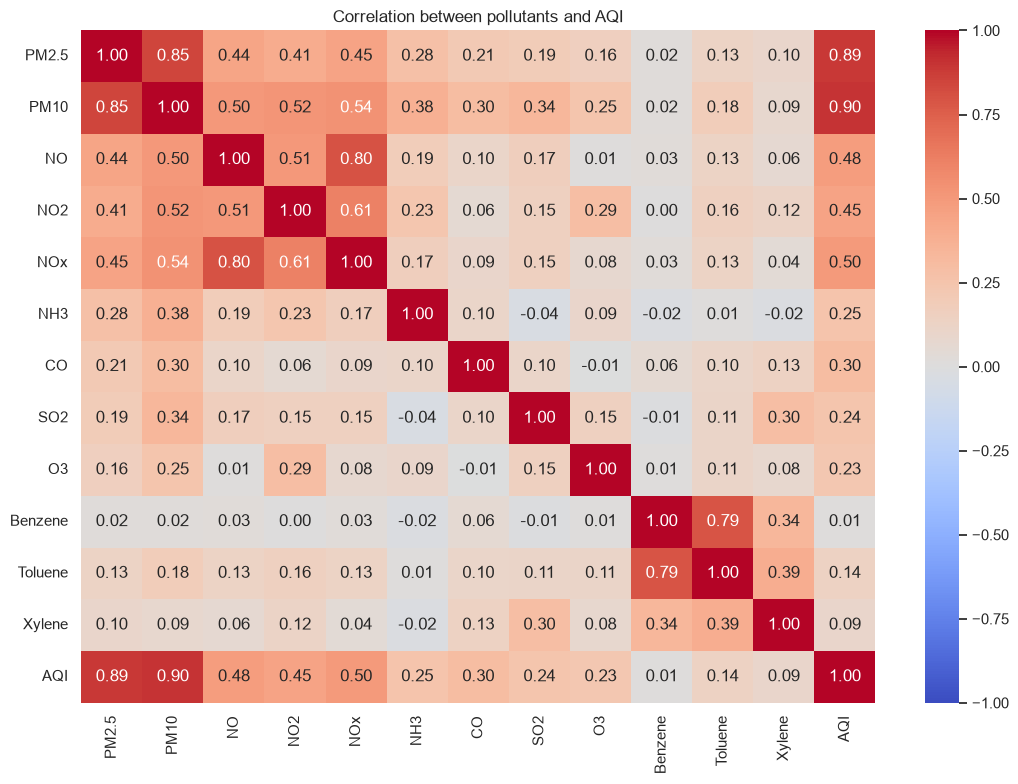

Correlation with AQI:
PM10       0.90
PM2.5      0.89
NOx        0.50
NO         0.48
NO2        0.45
CO         0.30
NH3        0.25
SO2        0.24
O3         0.23
Toluene    0.14
Xylene     0.09
Benzene    0.01
Name: AQI, dtype: float64


In [12]:
clean = df[~((df["City"] == "Ahmedabad") & (df["NO"] == df["CO"]))]

num_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
            "Benzene", "Toluene", "Xylene", "AQI"]
corr = clean[num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between pollutants and AQI")
plt.tight_layout()
plt.show()

print("Correlation with AQI:")
print(corr["AQI"].drop("AQI").sort_values(ascending=False).round(2))

**Insight:** PM10 (0.90) and PM2.5 (0.89) are by far the most related to AQI, which makes sense because particulate matter usually decides India's AQI on most days. The nitrogen oxides follow (about 0.45 to 0.50), while CO, NH3, SO2 and O3 are only weakly related (0.23 to 0.30). Benzene, Toluene and Xylene barely relate to AQI (0.01 to 0.14) and are mostly missing, which confirms leaving them out. NO and NOx overlap strongly with NO2, so NO2 alone represents that group.

### 5.1 Today's readings vs tomorrow's AQI

**What and why:** the app predicts **tomorrow's** AQI, so what really matters is how today's readings relate to tomorrow's AQI. We build tomorrow's AQI by shifting each city's AQI back one day (only where the next row is exactly one day later).

Correlation with tomorrow's AQI:
AQI      0.91
PM10     0.89
PM2.5    0.88
NO2      0.45
CO       0.29
NH3      0.25
SO2      0.24
O3       0.22
dtype: float64


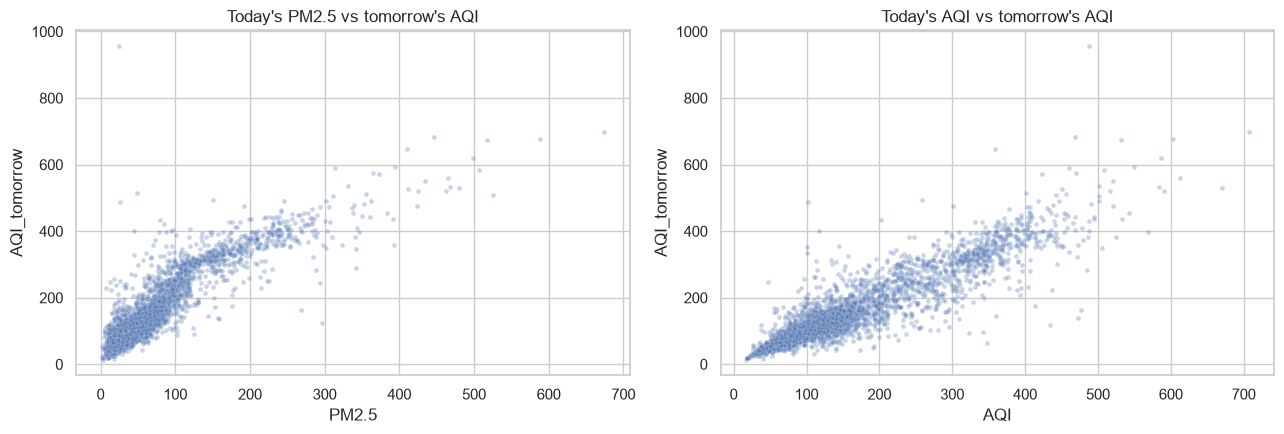

In [13]:
tmp = clean.sort_values(["City", "Date"]).copy()
tmp["AQI_tomorrow"] = tmp.groupby("City")["AQI"].shift(-1)
next_date = tmp.groupby("City")["Date"].shift(-1)
tmp.loc[(next_date - tmp["Date"]).dt.days != 1, "AQI_tomorrow"] = np.nan

print("Correlation with tomorrow's AQI:")
print(tmp[POLLUTANTS + ["AQI"]].corrwith(tmp["AQI_tomorrow"]).sort_values(ascending=False).round(2))

sample = tmp.dropna(subset=["PM2.5", "AQI_tomorrow"]).sample(4000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=sample, x="PM2.5", y="AQI_tomorrow", alpha=0.3, s=12, ax=axes[0])
axes[0].set_title("Today's PM2.5 vs tomorrow's AQI")
sns.scatterplot(data=sample, x="AQI", y="AQI_tomorrow", alpha=0.3, s=12, ax=axes[1])
axes[1].set_title("Today's AQI vs tomorrow's AQI")
plt.tight_layout()
plt.show()

**Insight:** Today's pollutants relate to tomorrow's AQI almost as strongly as to today's (PM10 0.89, PM2.5 0.88), because air quality changes slowly from one day to the next. Today's AQI itself is the strongest single signal (0.91). The model does not use it yet, because the app asks for pollutant readings only, but it is a clear candidate for a future 'lag' feature. The scatter plots fan out at high values, which warns that big AQI days will be harder to predict precisely.

## 6. Trends over time

**What and why:** air quality follows the calendar (winter smog, monsoon rain, weekday traffic). If clear time patterns exist, date features such as month and season are worth adding.

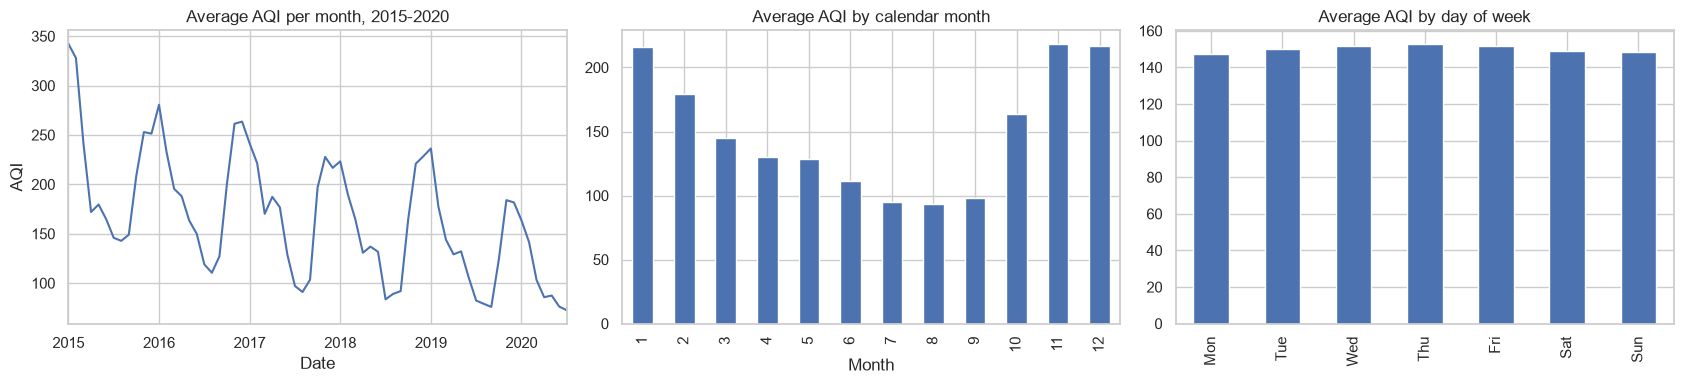

Average AQI by month:
Date
1     216.0
2     179.0
3     145.0
4     130.0
5     129.0
6     111.0
7      95.0
8      94.0
9      98.0
10    164.0
11    218.0
12    217.0
Name: AQI, dtype: float64

Average AQI by year:
Date
2015    196.0
2016    192.0
2017    173.0
2018    153.0
2019    138.0
2020    108.0
Name: AQI, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

clean.set_index("Date")["AQI"].resample("ME").mean().plot(ax=axes[0])
axes[0].set_title("Average AQI per month, 2015-2020")
axes[0].set_ylabel("AQI")

clean.groupby(clean["Date"].dt.month)["AQI"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Average AQI by calendar month")
axes[1].set_xlabel("Month")

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = clean.groupby(clean["Date"].dt.dayofweek)["AQI"].mean()
dow.index = days
dow.plot(kind="bar", ax=axes[2])
axes[2].set_title("Average AQI by day of week")

plt.tight_layout()
plt.show()

print("Average AQI by month:")
print(clean.groupby(clean["Date"].dt.month)["AQI"].mean().round(0))
print("\nAverage AQI by year:")
print(clean.groupby(clean["Date"].dt.year)["AQI"].mean().round(0))

**Insight:** There is a strong seasonal cycle. AQI averages about 216 to 218 in November to January (winter smog, still air, crop and heating fires) and falls to about 94 to 98 in July to September, when monsoon rain washes particles out of the air. Day of week barely matters (147 to 153), so weekday traffic is a small effect. Average AQI also fell every year, from 196 in 2015 to 108 in 2020, partly due to the 2020 COVID lockdown. This means month and season are worth adding as features, and that a time-based split is needed because the test years are cleaner than the training years.

## 7. City comparison

**What and why:** comparing cities shows which places most need a forecast, and whether one model can serve very different cities.

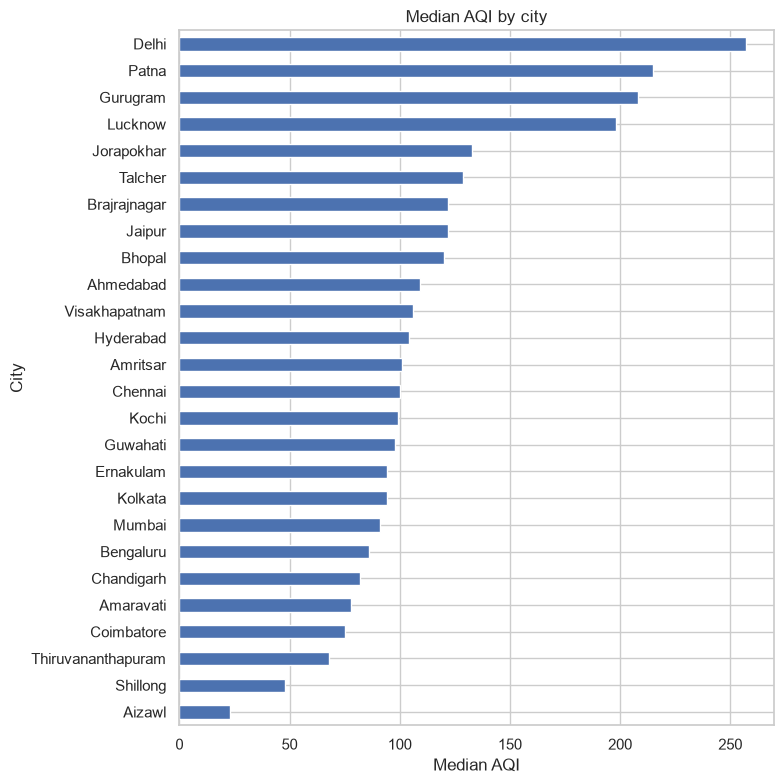

City
Delhi         257.0
Patna         215.0
Gurugram      208.0
Lucknow       198.0
Jorapokhar    133.0
Name: AQI, dtype: float64
City
Aizawl                23.0
Shillong              48.0
Thiruvananthapuram    68.0
Coimbatore            75.0
Amaravati             78.0
Name: AQI, dtype: float64


In [15]:
city_aqi = clean.groupby("City")["AQI"].median().sort_values()
city_aqi.plot(kind="barh", figsize=(8, 8), title="Median AQI by city")
plt.xlabel("Median AQI")
plt.tight_layout()
plt.show()

print(city_aqi.sort_values(ascending=False).round(0).head(5))
print(city_aqi.round(0).head(5))

**Insight:** Delhi (median 257), Patna (215), Gurugram (208) and Lucknow (198) are the most polluted cities, all in the Indo-Gangetic plain in the north. Aizawl (23), Shillong (48) and Thiruvananthapuram (68) are the cleanest. The gap between cities is huge, so a single model must cover very different conditions, and errors will likely be larger in the high-pollution cities.

## 8. Class balance of AQI categories

**What and why:** this is a regression task, but checking how many days fall in each AQI category tells us which ranges the model will see often and which are rare. Rare ranges are usually where a model makes its biggest errors.

AQI_Bucket
Good            1340
Satisfactory    8213
Moderate        8685
Poor            2544
Very Poor       2122
Severe           700
Name: count, dtype: int64
AQI_Bucket
Good             5.7
Satisfactory    34.8
Moderate        36.8
Poor            10.8
Very Poor        9.0
Severe           3.0
Name: count, dtype: float64


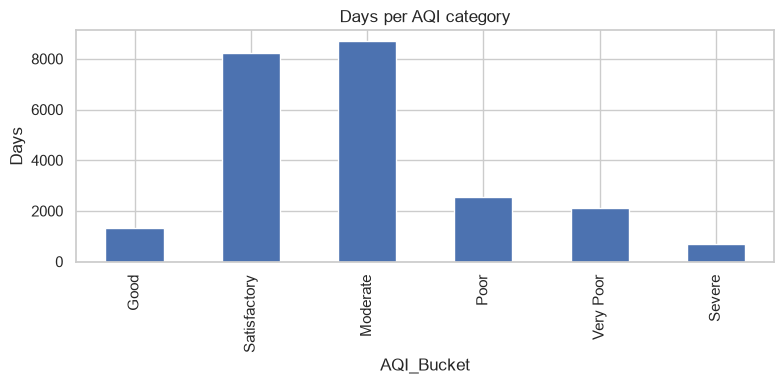

In [16]:
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
bucket = clean["AQI_Bucket"].value_counts().reindex(order)
print(bucket)
print((bucket / bucket.sum() * 100).round(1))

bucket.plot(kind="bar", figsize=(8, 4), title="Days per AQI category")
plt.ylabel("Days")
plt.tight_layout()
plt.show()

**Insight:** The data is imbalanced. Satisfactory and Moderate days make up about 72% of all days, while Severe days are only 3.0% and Good days 5.7%. The model will therefore see few examples of extreme pollution and is likely to be least accurate exactly on the days that matter most for health. This is checked in the error analysis of `02_modeling.ipynb`.

## 9. Summary: what EDA tells us to do

| Finding | Decision in `02_modeling.ipynb` |
|---|---|
| Many missing pollutant values | Fill with **medians learned from training data only** (inside a Pipeline) |
| Benzene, Toluene, Xylene mostly missing | Leave them out |
| AQI missing in 15.9% of rows | Drop rows with no target |
| Ahmedabad's CO column is a copy of NO | Drop those rows |
| AQI values above the official 500 limit | Cap AQI at 500 |
| No duplicate City + Date rows | Safe to build tomorrow's AQI by shifting one day |
| PM2.5 and PM10 are most related to AQI | Keep all 7 main pollutants as inputs |
| Strong winter / monsoon pattern | Add month, day of week and season features |
| Data is a time series | Split by date (train 2015-2018, test 2019-2020) and use time-based cross-validation |
| Severe days are rare | Expect larger errors at high AQI, and check this in error analysis |